# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [ ]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [ ]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!
import pandas as pd
metingen = pd.DataFrame({
    "Meting": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
    
    "Spanning voeding (V)": [
        None, None, None, None, None,
        None, None, None, None, None,
        None, None, None, None, None
    ],
    
    "Spanning 100R3 (V)": [
        None, None, None, None, None,
        None, None, None, None, None,
        None, None, None, None, None
    ]

     "Spanning 10R1 (V)": [s
            None, None, None, None, None,
            None, None, None, None, None,
            None, None, None, None, None
        ]
})


**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


Helling van het rechte deel: 23.02 1/V
Verzadigingsstroom (I_0):    9.99e-11 A
Berekende k_B:               1.381e-23 J/K


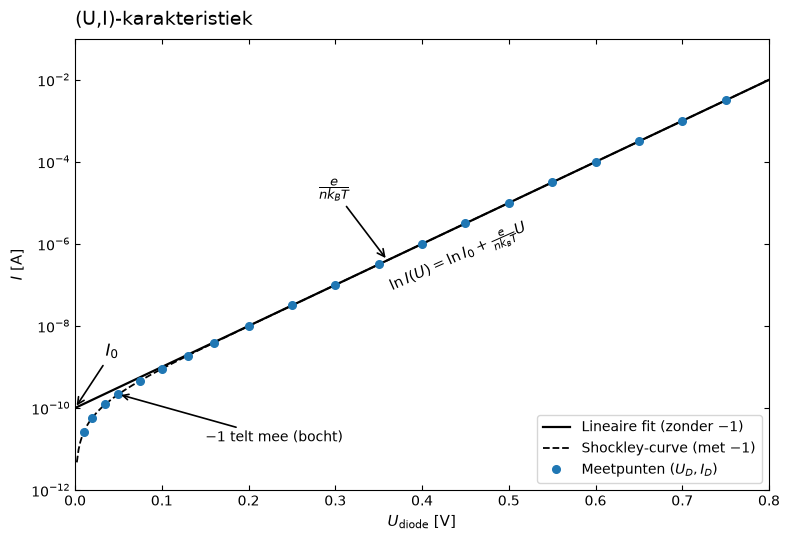

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. EXECUTION: Meetgegevens en constanten ---
R1 = 9990.6              # Exacte waarde van je 10 kΩ meetweerstand in Ohm (Ω)
T = 293.15               # Kamertemperatuur in Kelvin (bijv. 20 °C = 293.15 K)
e = 1.60217663e-19       # Elementaire lading in Coulomb (C)
n = 1.72                 # Idealiteitsfactor van de siliciumdiode

# Uitgebreide voorbeeldreeks (vanaf de bocht bij 0.01 V tot 0.75 V)
U_D = np.array([
    0.010, 0.020, 0.035, 0.050, 0.075, 0.100, 0.130, 0.160, 0.200,
    0.250, 0.300, 0.350, 0.400, 0.450, 0.500, 0.550, 0.600, 0.650, 0.700, 0.750
])

# Bijbehorende spanningen over R1 (in Volt) volgens de Shockley-vergelijking
I0_sim = 1.0e-10
helling_sim = e / (n * 1.380649e-23 * T)
U_R1 = R1 * I0_sim * (np.exp(helling_sim * U_D) - 1)

# --- 2. PROCESSING: Stroom en lineaire fit op het rechte deel ---
I_D = U_R1 / R1

# Fit ALLEEN het lineaire gebied (vanaf 0.30 V, waar de '-1' verwaarloosbaar is)
mask_lineair = U_D >= 0.30
helling, snijpunt = np.polyfit(U_D[mask_lineair], np.log(I_D[mask_lineair]), 1)

k_B_berekend = e / (n * T * helling)
I_0 = np.exp(snijpunt)

print(f"Helling van het rechte deel: {helling:.2f} 1/V")
print(f"Verzadigingsstroom (I_0):    {I_0:.2e} A")
print(f"Berekende k_B:               {k_B_berekend:.3e} J/K")

# --- 3. PLOTTEN: Exacte weergave zoals op de slide ---
U_lijn = np.linspace(0.0, 0.8, 400)
I_lineair_log = np.exp(helling * U_lijn + snijpunt)      # Rechte lijn (zonder -1)
I_exact = I_0 * (np.exp(helling * U_lijn) - 1)           # Shockley-curve (met -1)

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.semilogy(U_lijn, I_lineair_log, '-', color='black', linewidth=1.6, label='Lineaire fit (zonder $-1$)')
ax.semilogy(U_lijn[1:], I_exact[1:], '--', color='black', linewidth=1.3, label='Shockley-curve (met $-1$)')
ax.semilogy(U_D, I_D, 'o', color='tab:blue', markersize=5.5, label='Meetpunten $(U_D, I_D)$')

# Pijlen en formules plaatsen
ax.annotate(r'$I_0$', xy=(0.0, I_0), xytext=(0.035, I_0 * 18),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
            fontsize=12, fontweight='bold')

u_mid = 0.36
i_mid = np.exp(helling * u_mid + snijpunt)
ax.annotate(r'$\frac{e}{n k_B T}$', xy=(u_mid, i_mid), xytext=(0.28, i_mid * 45),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
            fontsize=13)

ax.text(0.36, np.exp(helling * 0.44 + snijpunt) * 0.03,
        r'$\ln I(U) = \ln I_0 + \frac{e}{n k_B T} U$',
        fontsize=11, rotation=24)

u_bocht = 0.05
i_bocht = I_0 * (np.exp(helling * u_bocht) - 1)
ax.annotate(r'$-1$ telt mee (bocht)', xy=(u_bocht, i_bocht), xytext=(0.15, 1.5e-11),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
            fontsize=10)

# Assen instellen
ax.set_title('(U,I)-karakteristiek', fontsize=14, loc='left', pad=10)
ax.set_xlabel(r'$U_{\mathrm{diode}}$ [V]', fontsize=11)
ax.set_ylabel(r'$I$ [A]', fontsize=11)

ax.set_xlim(0.0, 0.8)
ax.set_ylim(1e-12, 1e-1)
ax.set_xticks(np.arange(0.0, 0.81, 0.1))
ax.tick_params(direction='in', top=True, right=True, which='both')
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

In [ ]:
#Data processing and analysis:


In [ ]:
#Data processing and analysis:


**Describing the pattern in the processed data:**  


In [ ]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc